# Trabalho Final — Visão Computacional e Percepção
## Notebook 2 — Validação híbrida AR + MG

A pergunta é se treinar com as duas doenças e testar em amostras retidas das duas muda o resultado em relação ao zero-shot do notebook 1. Se mudar, o ganho vem do volume maior de treino, do teste MG contra MG, ou de outra coisa?

| Papel | Dataset | Doença | Amostras | Rótulo | Plataforma |
|---|---|---|---:|---|---|
| Treino | GSE106894 | Artrite reumatoide | 8 (4 R / 4 NR) | R/NR explícito | Affymetrix miRNA 4.0 |
| Treino | GSE131703 | Miastenia Gravis | 24 (12 R / 12 NR) | R/NR explícito | miRNA-seq |
| Teste | GSE106894 | Artrite reumatoide | 4 (2 R / 2 NR) | R/NR explícito | Affymetrix miRNA 4.0 |
| Teste | GSE131703 | Miastenia Gravis | 6 (3 R / 3 NR) | R/NR explícito | miRNA-seq |

O split é um holdout estratificado por doença e desfecho, com semente fixa. O notebook 1 (zero-shot) é a linha de base. Aqui o teste não é zero-shot, porque contém amostras das mesmas coortes usadas no treino.


## Raciocínio experimental

O notebook 1 treinou só em AR e testou só em MG, e o resultado ficou abaixo do acaso (AUC 0,436). Isso pode significar duas coisas: o sinal é específico de cada doença e não transfere, ou o modelo linear com 12 amostras não dá conta de uma relação possivelmente não linear.

Aqui o treino e o teste passam a ter as duas doenças. Com isso dá para separar três efeitos: o volume maior de treino (32 em vez de 12), o fato de parte do teste ser MG contra MG, e o que sobra depois de descontar os dois.

Se o desempenho continuar na mesma faixa do notebook 1, fica a suspeita de que o problema é o modelo, não só a transferência entre doenças. Se melhorar, ainda é preciso decompor o ganho antes de atribuir ao modelo.

Vale lembrar que este teste não é zero-shot: as amostras de teste vêm das mesmas coortes do treino, então o número é de holdout híbrido.


### Dependências

```bash
pip install pandas numpy scikit-learn matplotlib seaborn GEOparse openpyxl
```

In [1]:
# Bibliotecas padrão: logging, avisos, contagem e manipulação de caminhos.
import logging
import warnings
from collections import Counter
from pathlib import Path

# Bibliotecas de dados, gráficos e acesso aos datasets do GEO.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse
from IPython.display import display

# Componentes de modelagem, validação, métricas e seleção de features.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    LeaveOneOut,
    RepeatedStratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Configuração global: silencia avisos, define estilo dos gráficos e caminhos.
warnings.filterwarnings("ignore")
logging.getLogger("GEOparse").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
N_TEST_AR = 4
N_TEST_MG = 6
N_REPEATS = 50
RESULT_PREFIX = "vcp2"

DATA_DIR = Path("datasets")
RESULTS_DIR = Path("resultados")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Configuração concluída.")

Configuração concluída.


## Etapa 1 — Carregamento e anotação

Mesmas funções do notebook 1. Sondas Affymetrix viram nomes de miRNA, sondas repetidas são agregadas pela média e as contagens do GSE131703 passam por log-CPM. O alinhamento usa só a interseção dos nomes de miRNA, sem olhar rótulos.


In [2]:
def _download(url: str, path: Path) -> Path:
    '''Baixa um arquivo apenas se ele ainda não existir localmente.'''
    if not path.exists():
        import urllib.request
        urllib.request.urlretrieve(url, path)
    return path


def _parse_response(value) -> float:
    '''Converte o rótulo textual do GSE106894 para 1 (R) / 0 (NR).'''
    text = str(value).strip().lower()
    if text in {"responder", "r", "1"}:
        return 1.0
    if text in {"non-responder", "non responder", "nr", "0"}:
        return 0.0
    return np.nan


def _parse_mg_label(sample: str) -> float:
    '''Extrai o rótulo do GSE131703 a partir do nome da amostra.'''
    if "_NR" in sample:
        return 0.0
    if "_R" in sample:
        return 1.0
    return np.nan


def _log_cpm(counts: pd.DataFrame) -> pd.DataFrame:
    '''Normaliza contagens por log-CPM, adequado para dados de RNA-seq.'''
    library = counts.sum(axis=1).replace(0, np.nan)
    return np.log1p(counts.div(library, axis=0) * 1e6).fillna(0.0)


def load_gse106894(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE106894 e anota sondas Affymetrix como miRNAs.'''
    # Abre o dataset já baixado (ou baixa, se ainda não existir).
    gse = GEOparse.get_GEO(geo="GSE106894", destdir=str(data_dir), silent=True)

    # Matriz de expressão: linhas = amostras, colunas = sondas.
    expression = gse.pivot_samples("VALUE").T

    # Anotação da plataforma Affymetrix: ID da sonda -> nome do miRNA.
    platform = gse.gpls[next(iter(gse.gpls))]
    annotation = platform.table[["ID", "miRNA_ID"]].copy()
    annotation["ID"] = annotation["ID"].astype(str)
    annotation["miRNA_ID"] = (
        annotation["miRNA_ID"].fillna("").astype(str).str.strip()
    )
    annotation = annotation[annotation["miRNA_ID"] != ""].drop_duplicates("ID")
    probe_to_mirna = dict(zip(annotation["ID"], annotation["miRNA_ID"]))

    # Troca os IDs de sonda pelos nomes de miRNA.
    expression.columns = [
        probe_to_mirna.get(str(column), "") for column in expression.columns
    ]
    # Descarta sondas que não têm anotação de miRNA.
    expression = expression.loc[:, expression.columns != ""]
    # Várias sondas podem apontar para o mesmo miRNA; agrega pela média.
    expression = expression.T.groupby(level=0).mean().T
    expression = expression.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    # Lê o rótulo clínico de resposta ao tratamento (R/NR).
    metadata = gse.phenotype_data
    response_column = next(
        column for column in metadata.columns if "response" in column.lower()
    )
    labels = (
        metadata[response_column]
        .map(_parse_response)
        .reindex(expression.index)
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"
    labels.name = "response"

    # Devolve a matriz de expressão e o vetor de rótulos alinhados.
    return {
        "name": "GSE106894",
        "X": expression,
        "y": labels,
        "platform": "GPL21572",
    }

In [3]:
GSE131703_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE131nnn/GSE131703/suppl/"
    "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
)


def load_gse131703(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE131703 (miRNA-seq) e normaliza as contagens por log-CPM.'''
    # Garante que o arquivo XLSX de contagens esteja disponível localmente.
    path = _download(
        GSE131703_URL, data_dir / "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
    )
    # Lê a aba com as contagens brutas por miRNA.
    raw = pd.read_excel(path, sheet_name="mirna_rawcounts")

    # As colunas de amostra do arquivo começam com "MG_".
    sample_columns = [
        column for column in raw.columns if str(column).startswith("MG_")
    ]
    # Agrupa as contagens pelo nome do miRNA (pode haver mais de uma linha).
    counts = raw.groupby("Name")[sample_columns].sum()

    # Transpõe para o formato amostras x miRNAs e normaliza por log-CPM.
    expression = _log_cpm(counts.T.astype(float))
    expression.index = [str(sample) for sample in expression.index]

    # O rótulo está no nome da amostra: MG_R* = respondedor; MG_NR* = não-respondedor.
    labels = pd.Series(
        [_parse_mg_label(sample) for sample in expression.index],
        index=expression.index,
        name="response",
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"

    return {
        "name": "GSE131703",
        "X": expression,
        "y": labels,
        "platform": "miRNA-seq",
    }


def align_domains(source: dict, target: dict) -> tuple[dict, dict, list[str]]:
    '''Alinha treino e teste pela interseção de miRNAs, sem usar rótulos.'''
    # Interseção calculada apenas com nomes de miRNAs; não usa rótulos.
    common = sorted(set(source["X"].columns) & set(target["X"].columns))
    if not common:
        raise ValueError("Nenhum miRNA em comum entre treino e teste.")

    source_aligned = {**source, "X": source["X"].loc[:, common].copy()}
    target_aligned = {**target, "X": target["X"].loc[:, common].copy()}
    return source_aligned, target_aligned, common


def zscore_per_sample(X: pd.DataFrame) -> pd.DataFrame:
    '''Padroniza cada amostra (linha) entre os miRNAs, sem usar outras amostras.'''
    values = X.to_numpy(dtype=float)
    means = values.mean(axis=1, keepdims=True)
    stds = values.std(axis=1, keepdims=True)
    # Amostras constantes têm desvio zero; usa 1 para evitar divisão por zero.
    stds = np.where(stds == 0, 1.0, stds)
    normalized = (values - means) / stds
    return pd.DataFrame(normalized, index=X.index, columns=X.columns)

In [4]:
# Carrega as duas bases e mantém apenas os miRNAs presentes em ambas.
source = load_gse106894()
target = load_gse131703()
source, target, common_features = align_domains(source, target)

# Empilha as duas coortes já alinhadas no mesmo espaço de features, ainda
# sem a normalização por amostra (que ocorre na Etapa 2).
X_all = pd.concat([source["X"], target["X"]], axis=0)
y_all = pd.concat([source["y"], target["y"]], axis=0)
meta_all = pd.DataFrame(
    {
        "dataset": ["GSE106894"] * len(source["X"])
        + ["GSE131703"] * len(target["X"]),
        "response": np.concatenate(
            [source["y"].to_numpy(), target["y"].to_numpy()]
        ),
    },
    index=X_all.index,
)

# Quantidade de amostras na coorte de artrite reumatoide (AR).
N_AR = len(source["X"])

print(f"miRNAs em comum entre AR e MG: {len(common_features)}")


miRNAs em comum entre AR e MG: 2578


## Etapa 2 — Normalização por amostra

Normalização entra aqui, depois do carregamento/alinhamento e antes do split, da EDA e da modelagem. Cada amostra é padronizada entre seus próprios miRNAs (z-score por linha).

A ideia é tirar diferença global de escala entre amostras e plataformas, que senão domina a PCA e o SVM. Como é feito linha a linha, não usa rótulos nem outras amostras, então não vaza o teste. O StandardScaler do pipeline continua separado: ele é ajustado só no treino e padroniza por coluna.

A célula mostra média e desvio por amostra antes/depois e a PCA nas duas versões. O efeito nos resultados está na Etapa 11.


Média e desvio por amostra, antes e depois (média dentro da coorte):


,media_antes,desvio_antes,media_depois,desvio_depois
coorte,,,,
GSE106894,1.976,2.585,0.0,1.0
GSE131703,0.704,1.653,0.0,1.0


Após a normalização, a média por amostra fica em [-4.97e-15, 5.08e-15] e o desvio em [1.000, 1.000].


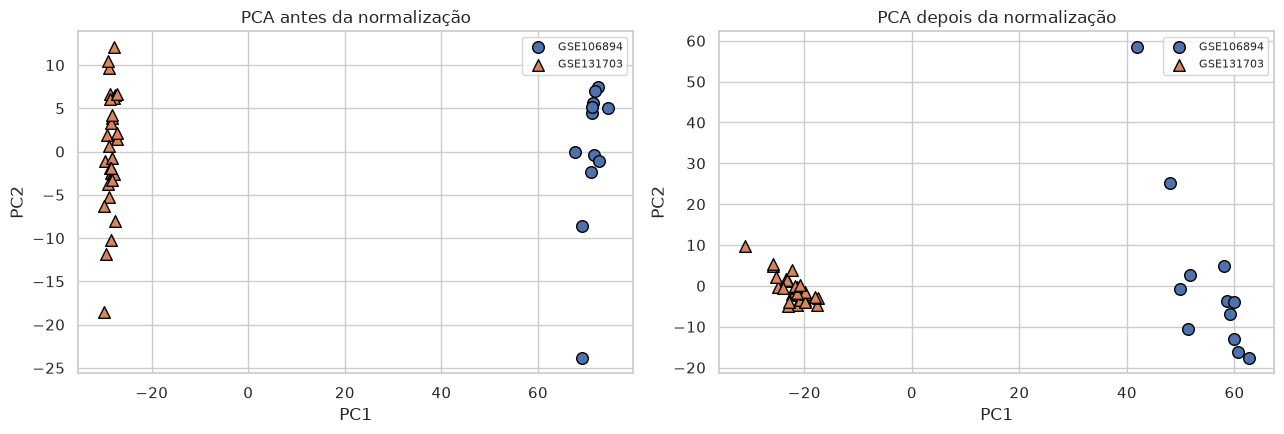

In [5]:
# Guarda os dados crus para comparar o efeito da normalização.
X_all_raw = X_all.copy()

# Aplica o z-score por amostra (linha a linha) antes da divisão e da EDA.
X_all = zscore_per_sample(X_all)

# Diagnóstico por coorte: média e desvio de cada amostra antes e depois.
diagnostico = pd.DataFrame(
    {
        "coorte": meta_all["dataset"],
        "media_antes": X_all_raw.mean(axis=1),
        "desvio_antes": X_all_raw.std(axis=1, ddof=0),
        "media_depois": X_all.mean(axis=1),
        "desvio_depois": X_all.std(axis=1, ddof=0),
    }
)

resumo_norm = (
    diagnostico.groupby("coorte")[
        ["media_antes", "desvio_antes", "media_depois", "desvio_depois"]
    ]
    .mean()
    .round(3)
)
print("Média e desvio por amostra, antes e depois (média dentro da coorte):")
display(resumo_norm)
print(
    "Após a normalização, a média por amostra fica em "
    f"[{diagnostico['media_depois'].min():.2e}, "
    f"{diagnostico['media_depois'].max():.2e}] e o desvio em "
    f"[{diagnostico['desvio_depois'].min():.3f}, "
    f"{diagnostico['desvio_depois'].max():.3f}]."
)

# PCA descritiva antes e depois da normalização (cor = coorte).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, data, title in [
    (axes[0], X_all_raw, "PCA antes da normalização"),
    (axes[1], X_all, "PCA depois da normalização"),
]:
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
        StandardScaler().fit_transform(data)
    )
    for domain, marker, color in [
        ("GSE106894", "o", "#4c72b0"),
        ("GSE131703", "^", "#dd8452"),
    ]:
        mask = (meta_all["dataset"] == domain).to_numpy()
        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            marker=marker,
            color=color,
            s=70,
            edgecolor="black",
            label=domain,
        )
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## Etapa 3 — Divisão híbrida e estratificada

O split é feito dentro de cada coorte e depois juntado: 4 R/4 NR de AR no treino e 2 R/2 NR no teste; 12 R/12 NR de MG no treino e 3 R/3 NR no teste. A semente é fixa. `X_all` já está normalizado desde a Etapa 2, e nada do teste entra no scaler, no LASSO ou no SVM.


In [6]:
def split_stratified_positions(
    y: pd.Series,
    n_ar: int,
    n_test_ar: int = N_TEST_AR,
    n_test_mg: int = N_TEST_MG,
    seed: int = RANDOM_STATE,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    '''Sorteia treino/teste dentro de AR e MG, estratificando pelo desfecho.'''
    y_array = np.asarray(y)
    ar_positions = np.arange(n_ar)
    mg_positions = np.arange(n_ar, len(y_array))

    ar_train, ar_test = train_test_split(
        ar_positions,
        test_size=n_test_ar,
        stratify=y_array[ar_positions],
        random_state=seed,
    )
    mg_train, mg_test = train_test_split(
        mg_positions,
        test_size=n_test_mg,
        stratify=y_array[mg_positions],
        random_state=seed,
    )
    return tuple(
        np.sort(part)
        for part in (ar_train, ar_test, mg_train, mg_test)
    )


# Divisão principal do notebook: semente fixa.
ar_train, ar_test, mg_train, mg_test = split_stratified_positions(
    y_all, N_AR, N_TEST_AR, N_TEST_MG, RANDOM_STATE
)
train_idx = np.concatenate([ar_train, mg_train])
test_idx = np.concatenate([ar_test, mg_test])

# Matrizes e metadados das partições.
X_train = X_all.iloc[train_idx]
y_train = y_all.iloc[train_idx]
meta_train = meta_all.iloc[train_idx]

X_test = X_all.iloc[test_idx]
y_test = y_all.iloc[test_idx]
meta_test = meta_all.iloc[test_idx]


def resumo_particao(meta: pd.DataFrame, nome: str) -> None:
    '''Imprime a composição de uma partição por coorte e desfecho.'''
    table = (
        pd.crosstab(meta["dataset"], meta["response"])
        .rename(columns={0: "NR", 1: "R"})
    )
    table["total"] = table.sum(axis=1)
    print(f"\n{nome} ({len(meta)} amostras)")
    print(table)


resumo_particao(meta_train, "Treino")
resumo_particao(meta_test, "Teste")

# Auditoria da divisão: permite reconstruir exatamente quem ficou onde.
particao = pd.Series(index=X_all.index, dtype=object)
particao.iloc[train_idx] = "treino"
particao.iloc[test_idx] = "teste"
split_audit = (
    meta_all.assign(particao=particao)
    .rename_axis("amostra")
    .reset_index()
)
split_audit.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_split_hibrido.csv", index=False
)

display(split_audit.head(10))


Treino (32 amostras)
response   NR   R  total
dataset                 
GSE106894   4   4      8
GSE131703  12  12     24

Teste (10 amostras)
response   NR  R  total
dataset                
GSE106894   2  2      4
GSE131703   3  3      6


,amostra,dataset,response,particao
0,GSM2857226,GSE106894,0,treino
1,GSM2857227,GSE106894,0,treino
2,GSM2857228,GSE106894,0,treino
3,GSM2857229,GSE106894,0,teste
4,GSM2857230,GSE106894,0,teste
5,GSM2857231,GSE106894,0,treino
6,GSM2857232,GSE106894,1,treino
7,GSM2857233,GSE106894,1,treino
8,GSM2857234,GSE106894,1,treino
9,GSM2857235,GSE106894,1,treino


## Etapa 4 — Análise exploratória

Só para conferir o balanceamento e ver se as coortes ocupam regiões diferentes na PCA. Se a separação por coorte for forte, provavelmente é efeito de plataforma/tecido e pode acabar dominando a classificação.


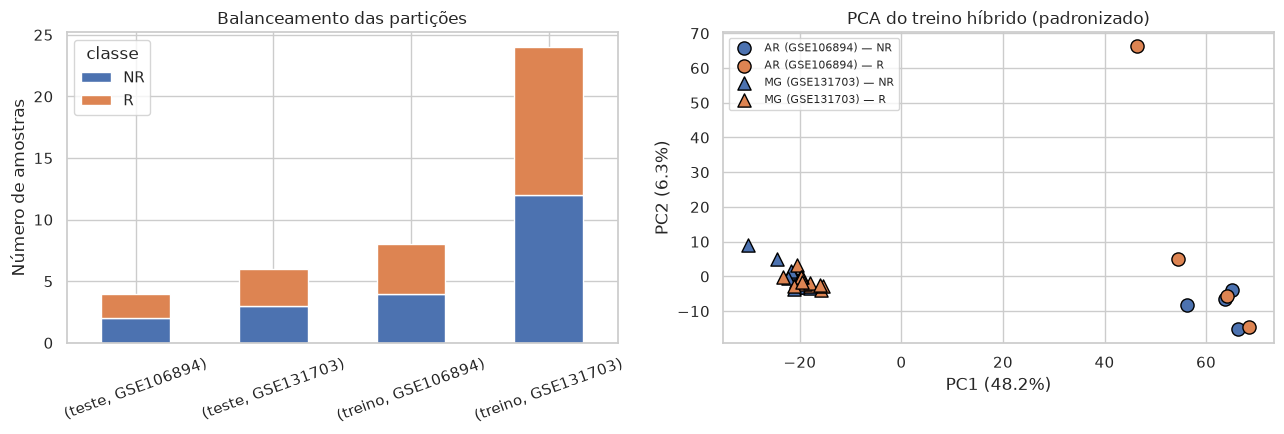

Variância explicada pelas duas primeiras PCs: 54.6%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Balanceamento por partição, coorte e classe.
balance = (
    split_audit.assign(classe=split_audit["response"].map({0: "NR", 1: "R"}))
    .groupby(["particao", "dataset", "classe"])
    .size()
    .unstack(fill_value=0)
)
balance.plot(
    kind="bar", stacked=True, ax=axes[0], color=["#4c72b0", "#dd8452"]
)
axes[0].set_title("Balanceamento das partições")
axes[0].set_ylabel("Número de amostras")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

# PCA do treino: cor = desfecho; marcador = coorte.
scaler_eda = StandardScaler().fit(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(scaler_eda.transform(X_train))

for domain, marker, domain_label in [
    ("GSE106894", "o", "AR (GSE106894)"),
    ("GSE131703", "^", "MG (GSE131703)"),
]:
    for response, color in [(0, "#4c72b0"), (1, "#dd8452")]:
        mask = (
            (meta_train["dataset"] == domain)
            & (meta_train["response"] == response)
        ).to_numpy()
        axes[1].scatter(
            pca_coords[mask, 0],
            pca_coords[mask, 1],
            marker=marker,
            color=color,
            s=90,
            edgecolor="black",
            label=f"{domain_label} — {'R' if response else 'NR'}",
        )
axes[1].set_title("PCA do treino híbrido (padronizado)")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].legend(fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

print(
    "Variância explicada pelas duas primeiras PCs: "
    f"{pca.explained_variance_ratio_[:2].sum():.1%}"
)

## Etapa 5 — Modelo: LASSO para seleção + SVM para classificação

Mesmo pipeline do notebook 1, sempre ajustado dentro do treino: StandardScaler, LASSO para escolher miRNAs com coeficiente não nulo (se zerar tudo, cai para os top-50) e SVC com `class_weight="balanced"` e `probability=True`. `alpha=0.05` e `C=1.0` ficam fixos como no notebook 1; o teste não é usado para tuning.

A CV repetida mostra a variação entre folds; o LOOCV com AUC agrupada dá uma estimativa interna menos ruidosa.


In [8]:
# Seletor de features baseado no LASSO, usado dentro do pipeline.
class LassoSelector(BaseEstimator, TransformerMixin):
    '''Seleciona features com coeficiente LASSO não nulo.

    Se o LASSO zerar todas as features, mantém as top-k por magnitude,
    evitando que o SVM receba uma matriz sem colunas.
    '''

    def __init__(self, alpha: float = 0.05, max_features: int = 50):
        self.alpha = alpha
        self.max_features = max_features

    def fit(self, X, y):
        X_array = np.asarray(X, dtype=float)
        y_array = np.asarray(y, dtype=float)

        # Ajusta o LASSO apenas no treino da partição atual.
        lasso = Lasso(alpha=self.alpha, max_iter=100000)
        lasso.fit(X_array, y_array)

        # Coeficientes não nulos indicam os miRNAs selecionados.
        importance = np.abs(lasso.coef_)
        mask = importance > 1e-8
        # Fallback: se o LASSO zerar tudo, mantém as top-k features.
        if not mask.any():
            mask = np.zeros_like(importance, dtype=bool)
            k = min(self.max_features, importance.size)
            mask[np.argsort(importance)[-k:]] = True

        # Guarda a máscara e os índices para transformar o conjunto de teste.
        self.support_ = mask
        self.selected_ = np.flatnonzero(mask)
        self.coef_ = lasso.coef_
        self.intercept_ = lasso.intercept_
        return self

    def transform(self, X):
        # Aplica a mesma máscara aprendida no treino.
        return np.asarray(X, dtype=float)[:, self.selected_]

    def get_support(self):
        return self.support_


# Baseline: padronização + SVM, sem seleção de features.
def make_svm(kernel: str = "linear", C: float = 1.0) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Modelo principal: padronização -> LASSO -> SVM.
def make_lasso_svm(
    kernel: str = "linear",
    C: float = 1.0,
    alpha: float = 0.05,
) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("lasso", LassoSelector(alpha=alpha, max_features=50)),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Calcula as métricas de classificação usadas no notebook.
def _metrics(y_true, y_pred, y_prob) -> dict:
    '''Calcula acurácia, F1 e AUC para classificação binária.'''
    y_true = np.asarray(y_true)
    auc = (
        roc_auc_score(y_true, y_prob)
        if len(np.unique(y_true)) == 2
        else np.nan
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": auc,
    }


# Estima o intervalo de confiança de 95% da AUC por bootstrap.
def bootstrap_auc_ci(
    y_true,
    y_prob,
    n_boot: int = 2000,
    seed: int = RANDOM_STATE,
) -> tuple[float, float]:
    '''Intervalo de confiança bootstrap de 95% para a AUC.'''
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    aucs = []

    for _ in range(n_boot):
        indices = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[indices])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[indices], y_prob[indices]))

    if not aucs:
        return np.nan, np.nan
    return tuple(np.percentile(aucs, [2.5, 97.5]))


# Modelos comparados na validação interna.
MODELS = {
    "SVM linear (baseline)": make_svm("linear"),
    "SVM RBF (baseline)": make_svm("rbf"),
    "LASSO + SVM linear": make_lasso_svm("linear"),
    "LASSO + SVM RBF": make_lasso_svm("rbf"),
}

print("Modelos definidos:", list(MODELS))

Modelos definidos: ['SVM linear (baseline)', 'SVM RBF (baseline)', 'LASSO + SVM linear', 'LASSO + SVM RBF']


### Etapa 5.1 — Validação cruzada repetida

5 folds, 20 repetições, 100 ajustes por modelo. Cada fold tem scaler e LASSO próprios.


In [9]:
# Validação cruzada estratificada repetida: 5 folds x 20 repetições.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=RANDOM_STATE,
)

# Avalia cada modelo em cada fold, sempre ajustando apenas no treino do fold.
cv_rows = []
for model_name, model in MODELS.items():
    for fold, (part_train, part_test) in enumerate(
        cv.split(X_train, y_train), start=1
    ):
        fitted = model.fit(
            X_train.iloc[part_train], y_train.iloc[part_train]
        )
        y_pred = fitted.predict(X_train.iloc[part_test])
        y_prob = fitted.predict_proba(X_train.iloc[part_test])[:, 1]

        cv_rows.append(
            {
                "model": model_name,
                "fold": fold,
                "n_train": len(part_train),
                "n_test": len(part_test),
                **_metrics(
                    y_train.iloc[part_test], y_pred, y_prob
                ),
            }
        )

# Guarda os resultados por fold e o resumo agregado.
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_cv_repetida.csv", index=False
)

cv_summary = (
    cv_results.groupby("model")[["accuracy", "f1", "auc"]]
    .agg(["mean", "std"])
    .round(3)
)
display(cv_summary)

accuracy            f1           auc       
                          mean    std   mean    std   mean    std
model                                                            
LASSO + SVM RBF          0.523  0.182  0.500  0.243  0.510  0.213
LASSO + SVM linear       0.533  0.183  0.524  0.231  0.539  0.232
SVM RBF (baseline)       0.410  0.148  0.434  0.219  0.458  0.190
SVM linear (baseline)    0.494  0.178  0.480  0.223  0.442  0.212

### Etapa 5.2 — LOOCV com AUC agrupada

Uma amostra do treino fica de fora por vez. As probabilidades out-of-sample são juntadas e a AUC é calculada uma vez sobre as 32 amostras, em vez de tirar média de AUCs de folds pequenos.


In [10]:
# LOOCV: cada amostra do treino é deixada de fora uma vez.
loo = LeaveOneOut()
loocv_rows = []
loocv_probabilities = {}

# Gera uma probabilidade fora da amostra para cada paciente do treino.
for model_name, model in MODELS.items():
    y_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=loo,
        method="predict_proba",
    )[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # Calcula a AUC agrupada e o intervalo de confiança bootstrap.
    auc_low, auc_high = bootstrap_auc_ci(y_train.values, y_prob)
    loocv_probabilities[model_name] = y_prob
    loocv_rows.append(
        {
            "model": model_name,
            **_metrics(y_train.values, y_pred, y_prob),
            "auc_ci_low": auc_low,
            "auc_ci_high": auc_high,
        }
    )

loocv_results = pd.DataFrame(loocv_rows)
loocv_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_loocv.csv", index=False
)
display(loocv_results.round(3))

,model,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,SVM linear (baseline),0.219,0.000,0.254,0.086,0.467
1,SVM RBF (baseline),0.188,0.316,0.256,0.077,0.475
2,LASSO + SVM linear,0.500,0.529,0.523,0.305,0.733
3,LASSO + SVM RBF,0.469,0.541,0.559,0.352,0.764


### Etapa 5.3 — Estabilidade da seleção LASSO

Conta em quantos dos 100 folds cada miRNA foi selecionado. Frequência ≥ 0,70 é o critério usual de estabilidade.


Folds avaliados: 100
miRNAs selecionados ao menos uma vez: 241
Frequência máxima de seleção: 90.0%
miRNAs com frequência >= 70%: 2
miRNAs com frequência >= 50%: 6


,feature,n_folds,frequency
9,hsa-miR-545-5p,90,0.90
31,hsa-miR-6825-3p,76,0.76
6,hsa-miR-4712-5p,58,0.58
4,hsa-miR-409-3p,56,0.56
41,hsa-miR-370-3p,52,0.52
57,hsa-miR-585-5p,52,0.52
15,hsa-miR-6516-3p,49,0.49
33,hsa-miR-7-1-3p,49,0.49
0,hsa-miR-1278,48,0.48
13,hsa-miR-6503-3p,46,0.46


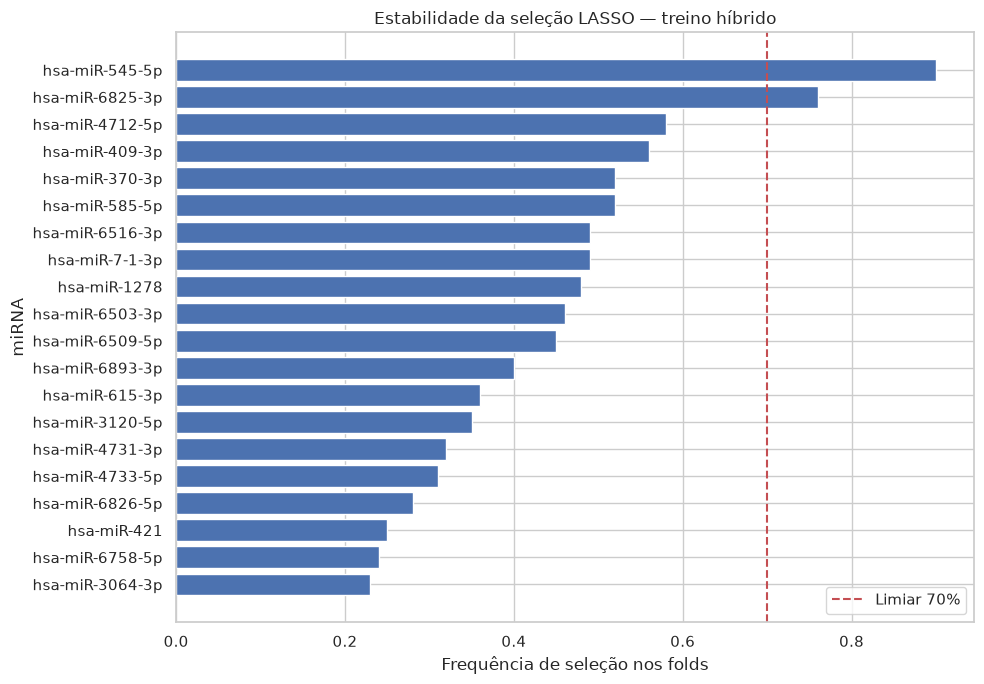

In [11]:
# Conta em quantos folds cada miRNA foi selecionado pelo LASSO.
stability_counts = Counter()
n_folds = 0

# Reajusta o LASSO em cada fold de treino da validação cruzada.
for part_train, _ in cv.split(X_train, y_train):
    fitted = make_lasso_svm("linear").fit(
        X_train.iloc[part_train], y_train.iloc[part_train]
    )
    support = fitted.named_steps["lasso"].get_support()
    for feature in X_train.columns[support]:
        stability_counts[feature] += 1
    n_folds += 1

# Frequência = folds em que o miRNA foi selecionado / total de folds.
stability = pd.DataFrame(
    [
        {"feature": feature, "n_folds": count, "frequency": count / n_folds}
        for feature, count in stability_counts.items()
    ]
).sort_values(["frequency", "feature"], ascending=[False, True])

stability.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_estabilidade_lasso.csv", index=False
)

# Indicadores de estabilidade: frequência máxima e limiares de 50% e 70%.
max_frequency = stability["frequency"].max() if not stability.empty else 0.0
n_stable_70 = int((stability["frequency"] >= 0.70).sum())
n_stable_50 = int((stability["frequency"] >= 0.50).sum())

print(f"Folds avaliados: {n_folds}")
print(f"miRNAs selecionados ao menos uma vez: {len(stability)}")
print(f"Frequência máxima de seleção: {max_frequency:.1%}")
print(f"miRNAs com frequência >= 70%: {n_stable_70}")
print(f"miRNAs com frequência >= 50%: {n_stable_50}")

display(stability.head(20).round(3))

# Gráfico dos 20 miRNAs mais frequentes nos folds.
top_stability = stability.head(20).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_stability["feature"], top_stability["frequency"], color="#4c72b0")
plt.axvline(0.70, color="#c44e52", linestyle="--", label="Limiar 70%")
plt.xlabel("Frequência de seleção nos folds")
plt.ylabel("miRNA")
plt.title("Estabilidade da seleção LASSO — treino híbrido")
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 6 — Modelo final e assinatura

Treina o modelo final nas 32 amostras do treino com a configuração que veio da CV. A assinatura são os miRNAs com coeficiente LASSO diferente de zero; os pesos do SVM linear só indicam a direção de cada um.


In [12]:
# Treina o modelo final em todas as amostras do treino híbrido.
final_model = make_lasso_svm("linear", C=1.0, alpha=0.05).fit(
    X_train, y_train
)

# Recupera a máscara do LASSO e os coeficientes do SVM linear.
support = final_model.named_steps["lasso"].get_support()
selected_features = X_train.columns[support]
svm_coefficients = final_model.named_steps["svm"].coef_.ravel()
lasso_coefficients = final_model.named_steps["lasso"].coef_[support]

# Monta a tabela da assinatura final.
signature = pd.DataFrame(
    {
        "feature": selected_features,
        "lasso_coefficient": lasso_coefficients,
        "svm_coefficient": svm_coefficients,
    }
)
# Ordena pelos pesos absolutos do SVM.
signature["abs_svm_coefficient"] = signature["svm_coefficient"].abs()
signature = signature.sort_values(
    "abs_svm_coefficient", ascending=False
).reset_index(drop=True)

signature.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_assinatura_mirnas.csv", index=False
)
print(f"miRNAs selecionados pelo LASSO final: {len(signature)}")
display(signature.round(4))

miRNAs selecionados pelo LASSO final: 22


,feature,lasso_coefficient,svm_coefficient,abs_svm_coefficient
0,hsa-miR-545-5p,-0.1246,-0.3624,0.3624
1,hsa-miR-6826-5p,-0.0481,-0.2854,0.2854
2,hsa-miR-370-3p,0.0599,0.2453,0.2453
3,hsa-miR-3064-3p,0.0492,0.2349,0.2349
4,hsa-miR-409-3p,0.0754,0.2346,0.2346
5,hsa-miR-4712-5p,-0.0988,-0.2161,0.2161
6,hsa-miR-6825-3p,0.0642,0.1682,0.1682
7,hsa-miR-585-5p,-0.0734,-0.1666,0.1666
8,hsa-miR-7-1-3p,-0.0565,-0.1635,0.1635
9,hsa-miR-6516-3p,0.0705,0.1414,0.1414


## Etapa 7 — Teste no holdout híbrido

O modelo é congelado e aplicado às 10 amostras retidas (4 AR + 6 MG). Sem re-treino, sem re-escalonar com o teste, sem re-selecionar features e sem mexer no limiar de 0,5.

Como o teste mistura coortes, o resultado sai no total e separado por coorte. Um AUC agregado pode esconder que o desempenho vem só de MG.


Métricas do holdout híbrido (10 amostras):
  accuracy: 0.700
  f1: 0.727
  auc: 0.760
  AUC IC95% bootstrap: [0.375, 1.000]
  Previstos como respondedores: 6/10
  Acurácia de um classificador trivial que prevê não-respondedor: 0.500


,coorte,n,n_R,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,GSE106894,4,2,0.750,0.800,1.000,1.0,1.0
1,GSE131703,6,3,0.667,0.667,0.667,0.0,1.0



Relatório de classificação — holdout híbrido:
                 precision    recall  f1-score   support

Não-respondedor      0.750     0.600     0.667         5
    Respondedor      0.667     0.800     0.727         5

       accuracy                          0.700        10
      macro avg      0.708     0.700     0.697        10
   weighted avg      0.708     0.700     0.697        10



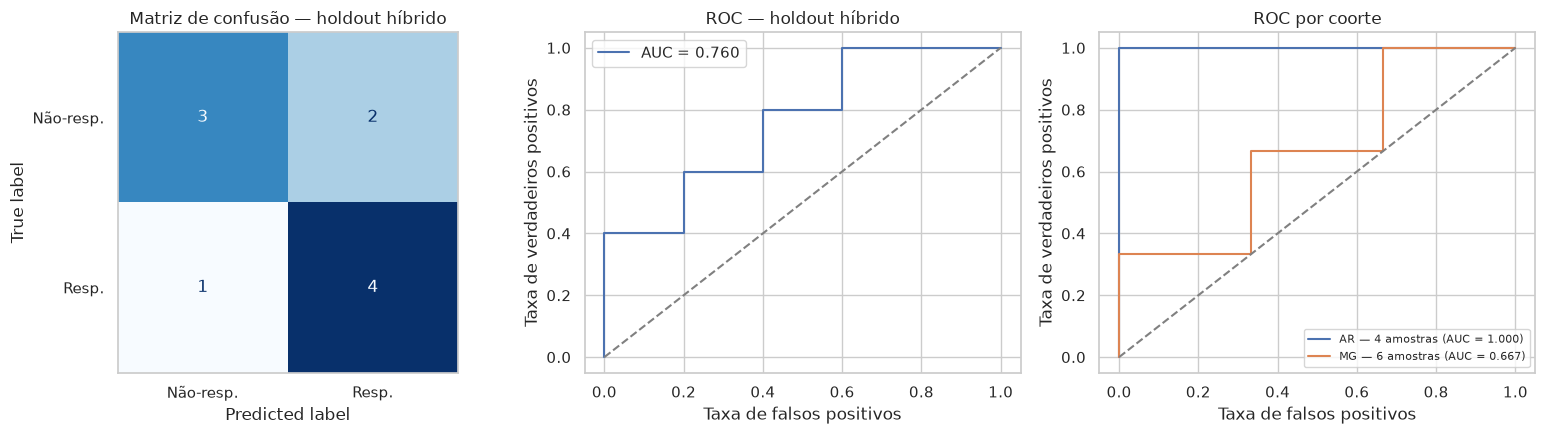

,coorte,amostra,y_true,y_pred,probabilidade
0,GSE106894,GSM2857229,0,0,0.261018
1,GSE106894,GSM2857230,0,1,0.958062
2,GSE106894,GSM2857236,1,1,0.983327
3,GSE106894,GSM2857237,1,1,0.990379
4,GSE131703,MG_NR4,0,0,0.443975
5,GSE131703,MG_R9,1,1,0.846219
6,GSE131703,MG_NR15,0,0,0.284862
7,GSE131703,MG_R12,1,1,0.537552
8,GSE131703,MG_NR5,0,1,0.563638
9,GSE131703,MG_R15,1,0,0.288317


In [13]:
# Aplica o modelo congelado ao holdout híbrido, sem re-treino ou ajuste.
y_prob_holdout = final_model.predict_proba(X_test)[:, 1]
y_pred_holdout = final_model.predict(X_test)

# Calcula as métricas do conjunto todo e o IC bootstrap da AUC.
holdout_metrics = _metrics(y_test, y_pred_holdout, y_prob_holdout)
auc_low, auc_high = bootstrap_auc_ci(y_test.values, y_prob_holdout)

print("Métricas do holdout híbrido (10 amostras):")
for metric, value in holdout_metrics.items():
    print(f"  {metric}: {value:.3f}")
print(f"  AUC IC95% bootstrap: [{auc_low:.3f}, {auc_high:.3f}]")
print(
    f"  Previstos como respondedores: "
    f"{int(y_pred_holdout.sum())}/{len(y_pred_holdout)}"
)
print(
    "  Acurácia de um classificador trivial que prevê não-respondedor: "
    f"{accuracy_score(y_test, np.zeros_like(y_test)):.3f}"
)

# Métricas por coorte, usando o mesmo modelo congelado.
def evaluate_domain(domain: str) -> dict:
    '''Calcula métricas do holdout restritas a uma coorte.'''
    mask = (meta_test["dataset"] == domain).to_numpy()
    y_true_domain = y_test.to_numpy()[mask]
    y_pred_domain = y_pred_holdout[mask]
    y_prob_domain = y_prob_holdout[mask]
    low, high = bootstrap_auc_ci(y_true_domain, y_prob_domain)
    return {
        "coorte": domain,
        "n": int(mask.sum()),
        "n_R": int(y_true_domain.sum()),
        ** _metrics(y_true_domain, y_pred_domain, y_prob_domain),
        "auc_ci_low": low,
        "auc_ci_high": high,
    }


domain_results = pd.DataFrame(
    [evaluate_domain(domain) for domain in ["GSE106894", "GSE131703"]]
)
display(domain_results.round(3))

# Relatório de precisão, recall e F1 por classe.
print("\nRelatório de classificação — holdout híbrido:")
print(
    classification_report(
        y_test,
        y_pred_holdout,
        target_names=["Não-respondedor", "Respondedor"],
        digits=3,
        zero_division=0,
    )
)

# Matriz de confusão e curvas ROC (conjunto todo e por coorte).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cm = confusion_matrix(y_test, y_pred_holdout)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Não-resp.", "Resp."],
).plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusão — holdout híbrido")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob_holdout)
axes[1].plot(
    fpr, tpr, label=f"AUC = {holdout_metrics['auc']:.3f}", color="#4c72b0"
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de falsos positivos")
axes[1].set_ylabel("Taxa de verdadeiros positivos")
axes[1].set_title("ROC — holdout híbrido")
axes[1].legend()

for domain, color, label in [
    ("GSE106894", "#4c72b0", "AR — 4 amostras"),
    ("GSE131703", "#dd8452", "MG — 6 amostras"),
]:
    mask = (meta_test["dataset"] == domain).to_numpy()
    y_true_domain = y_test.to_numpy()[mask]
    y_prob_domain = y_prob_holdout[mask]
    fpr_d, tpr_d, _ = roc_curve(y_true_domain, y_prob_domain)
    auc_d = roc_auc_score(y_true_domain, y_prob_domain)
    axes[2].plot(fpr_d, tpr_d, color=color, label=f"{label} (AUC = {auc_d:.3f})")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[2].set_xlabel("Taxa de falsos positivos")
axes[2].set_ylabel("Taxa de verdadeiros positivos")
axes[2].set_title("ROC por coorte")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Salva as previsões por amostra para auditoria.
previsoes = pd.DataFrame(
    {
        "coorte": meta_test["dataset"].to_numpy(),
        "amostra": X_test.index,
        "y_true": y_test.to_numpy(),
        "y_pred": y_pred_holdout,
        "probabilidade": y_prob_holdout,
    }
)
previsoes.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_previsoes_holdout.csv", index=False
)
display(previsoes)

## Etapa 8 — De onde vem o ganho? Ablação de volume e domínio

Ajusta o mesmo pipeline em recortes do treino e testa nos recortes correspondentes:

| Configuração | O que isola |
|---|---|
| AR (8) → AR (4) | mesma doença, treino pequeno |
| MG (24) → MG (6) | mesma doença, treino maior |
| AR (8) → MG (6) | troca de doença, treino pequeno (análogo ao notebook 1) |
| MG (24) → AR (4) | troca de doença, treino maior |
| Híbrido (32) → AR (4) | efeito de adicionar MG ao treino, testando AR |
| Híbrido (32) → MG (6) | efeito de adicionar AR ao treino, testando MG |
| Híbrido (32) → Híbrido (10) | resultado principal deste notebook |

Se MG→MG ficar muito acima de AR→MG, o ganho é compatibilidade de domínio. Se o híbrido ganhar dos treinos de uma doença só nos dois testes, é volume/interação. Se nada passar claramente do acaso, sobra a hipótese de limitação do modelo linear.


In [14]:
def evaluate_config(
    name: str,
    config_train_idx: np.ndarray,
    config_test_idx: np.ndarray,
) -> dict:
    '''Ajusta o pipeline no treino da configuração e avalia no teste dela.'''
    model = make_lasso_svm("linear", C=1.0, alpha=0.05)
    fitted = model.fit(
        X_all.iloc[config_train_idx], y_all.iloc[config_train_idx]
    )
    y_prob = fitted.predict_proba(X_all.iloc[config_test_idx])[:, 1]
    y_pred = fitted.predict(X_all.iloc[config_test_idx])
    y_true = y_all.iloc[config_test_idx].to_numpy()
    low, high = bootstrap_auc_ci(y_true, y_prob)

    return {
        "configuracao": name,
        "n_train": len(config_train_idx),
        "n_test": len(config_test_idx),
        "n_mirnas_selecionados": int(
            fitted.named_steps["lasso"].get_support().sum()
        ),
        **_metrics(y_true, y_pred, y_prob),
        "auc_ci_low": low,
        "auc_ci_high": high,
    }


# Configurações de ablação sobre a divisão principal.
ABLATION_CONFIGS = {
    "AR (8) -> AR (4)": (ar_train, ar_test),
    "MG (24) -> MG (6)": (mg_train, mg_test),
    "AR (8) -> MG (6)": (ar_train, mg_test),
    "MG (24) -> AR (4)": (mg_train, ar_test),
    "Híbrido (32) -> AR (4)": (train_idx, ar_test),
    "Híbrido (32) -> MG (6)": (train_idx, mg_test),
    "Híbrido (32) -> Híbrido (10)": (train_idx, test_idx),
}

ablation_results = pd.DataFrame(
    [
        evaluate_config(name, config_train, config_test)
        for name, (config_train, config_test) in ABLATION_CONFIGS.items()
    ]
)
ablation_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_ablacao.csv", index=False
)
display(ablation_results.round(3))

,configuracao,n_train,n_test,n_mirnas_selecionados,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,AR (8) -> AR (4),8,4,6,0.500,0.500,0.500,0.000,1.0
1,MG (24) -> MG (6),24,6,19,1.000,1.000,1.000,1.000,1.0
2,AR (8) -> MG (6),8,6,6,0.500,0.000,0.444,0.000,1.0
3,MG (24) -> AR (4),24,4,19,0.500,0.667,0.500,0.500,0.5
4,Híbrido (32) -> AR (4),32,4,22,0.750,0.800,1.000,1.000,1.0
5,Híbrido (32) -> MG (6),32,6,22,0.667,0.667,0.667,0.000,1.0
6,Híbrido (32) -> Híbrido (10),32,10,22,0.700,0.727,0.760,0.375,1.0


### Etapa 8.1 — Sensibilidade à divisão aleatória

Com 4 amostras de AR e 6 de MG no teste, uma divisão só é ruído demais. As configurações são repetidas em 50 splits estratificados com sementes diferentes, e o resultado vira média ± desvio da AUC, além da fração de splits com AUC > 0,5.


In [15]:
# Reavalia as configurações em várias divisões estratificadas.
sensitivity_rows = []
for repetition, seed in enumerate(
    range(RANDOM_STATE, RANDOM_STATE + N_REPEATS)
):
    ar_tr, ar_te, mg_tr, mg_te = split_stratified_positions(
        y_all, N_AR, N_TEST_AR, N_TEST_MG, seed
    )
    hybrid_train = np.concatenate([ar_tr, mg_tr])
    hybrid_test = np.concatenate([ar_te, mg_te])
    configs = {
        "AR (8) -> AR (4)": (ar_tr, ar_te),
        "MG (24) -> MG (6)": (mg_tr, mg_te),
        "AR (8) -> MG (6)": (ar_tr, mg_te),
        "MG (24) -> AR (4)": (mg_tr, ar_te),
        "Híbrido (32) -> AR (4)": (hybrid_train, ar_te),
        "Híbrido (32) -> MG (6)": (hybrid_train, mg_te),
        "Híbrido (32) -> Híbrido (10)": (hybrid_train, hybrid_test),
    }

    for name, (config_train, config_test) in configs.items():
        model = make_lasso_svm("linear", C=1.0, alpha=0.05)
        fitted = model.fit(
            X_all.iloc[config_train], y_all.iloc[config_train]
        )
        y_prob = fitted.predict_proba(X_all.iloc[config_test])[:, 1]
        y_pred = fitted.predict(X_all.iloc[config_test])

        sensitivity_rows.append(
            {
                "repeticao": repetition,
                "seed": seed,
                "configuracao": name,
                "n_train": len(config_train),
                "n_test": len(config_test),
                **_metrics(
                    y_all.iloc[config_test].to_numpy(), y_pred, y_prob
                ),
            }
        )

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_sensibilidade_divisoes.csv", index=False
)

# Resumo por configuração: média, desvio e taxa de AUC > 0,5.
sensitivity_summary = (
    sensitivity.groupby("configuracao")
    .agg(
        n_repeticoes=("auc", "size"),
        n_train=("n_train", "first"),
        n_test=("n_test", "first"),
        accuracy_media=("accuracy", "mean"),
        accuracy_desvio=("accuracy", "std"),
        auc_media=("auc", "mean"),
        auc_desvio=("auc", "std"),
        auc_acima_0_5=("auc", lambda values: (values > 0.5).mean()),
    )
    .round(3)
)
sensitivity_summary.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_sensibilidade_resumo.csv"
)
display(sensitivity_summary)

,n_repeticoes,n_train,n_test,accuracy_media,accuracy_desvio,auc_media,auc_desvio,auc_acima_0_5
configuracao,,,,,,,,
AR (8) -> AR (4),50,8,4,0.455,0.251,0.415,0.334,0.26
AR (8) -> MG (6),50,8,6,0.503,0.086,0.509,0.273,0.56
Híbrido (32) -> AR (4),50,32,4,0.555,0.191,0.575,0.320,0.40
Híbrido (32) -> Híbrido (10),50,32,10,0.602,0.130,0.651,0.182,0.76
Híbrido (32) -> MG (6),50,32,6,0.633,0.168,0.720,0.231,0.86
MG (24) -> AR (4),50,24,4,0.505,0.035,0.500,0.204,0.18
MG (24) -> MG (6),50,24,6,0.680,0.181,0.738,0.230,0.84


## Etapa 9 — Comparação com o notebook 1

Junta as estimativas internas e externas dos dois notebooks. A referência é o zero-shot do notebook 1 (treino em 12 AR, teste em 30 MG); as linhas do notebook 2 são da execução com z-score por amostra e mostram o holdout híbrido e as coortes separadas.


,notebook,n_treino,n_teste,accuracy,f1,auc
0,1 — Zero-Shot AR -> MG,12,30,0.500,0.000,0.436
1,1 — LOOCV interno AR,12,12,0.417,0.533,0.417
2,2 — LOOCV interno híbrido,32,32,0.500,0.529,0.523
3,2 — Holdout híbrido,32,10,0.700,0.727,0.760
4,2 — Holdout GSE106894 (4),32,4,0.750,0.800,1.000
5,2 — Holdout GSE131703 (6),32,6,0.667,0.667,0.667


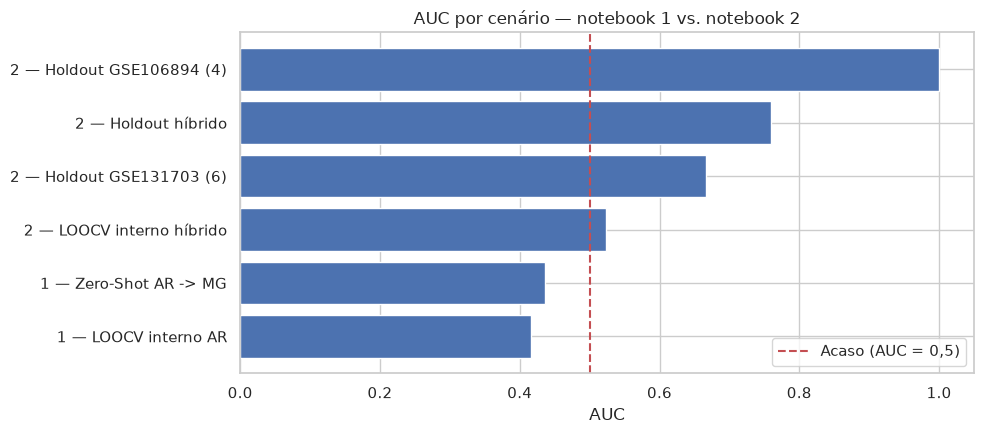

In [16]:
# Lê os resultados salvos pelo notebook 1, se existirem.
nb1_loocv_path = RESULTS_DIR / "vcp_loocv.csv"
nb1_summary_path = RESULTS_DIR / "vcp_resumo_metricas.csv"
nb1_loocv = pd.read_csv(nb1_loocv_path)
nb1_summary = pd.read_csv(nb1_summary_path)

nb1_zero = nb1_summary.loc[
    nb1_summary["etapa"].str.contains("Zero-Shot")
].iloc[0]
nb1_loo = nb1_loocv.loc[
    nb1_loocv["model"] == "LASSO + SVM linear"
].iloc[0]
nb2_loo = loocv_results.loc[
    loocv_results["model"] == "LASSO + SVM linear"
].iloc[0]

comparison_rows = [
    {
        "notebook": "1 — Zero-Shot AR -> MG",
        "n_treino": 12,
        "n_teste": 30,
        "accuracy": nb1_zero["accuracy"],
        "f1": nb1_zero["f1"],
        "auc": nb1_zero["auc"],
    },
    {
        "notebook": "1 — LOOCV interno AR",
        "n_treino": 12,
        "n_teste": 12,
        "accuracy": nb1_loo["accuracy"],
        "f1": nb1_loo["f1"],
        "auc": nb1_loo["auc"],
    },
    {
        "notebook": "2 — LOOCV interno híbrido",
        "n_treino": 32,
        "n_teste": 32,
        "accuracy": nb2_loo["accuracy"],
        "f1": nb2_loo["f1"],
        "auc": nb2_loo["auc"],
    },
    {
        "notebook": "2 — Holdout híbrido",
        "n_treino": len(train_idx),
        "n_teste": len(test_idx),
        "accuracy": holdout_metrics["accuracy"],
        "f1": holdout_metrics["f1"],
        "auc": holdout_metrics["auc"],
    },
]

# Acrescenta as coortes separadas do holdout.
for _, row in domain_results.iterrows():
    comparison_rows.append(
        {
            "notebook": f"2 — Holdout {row['coorte']} ({row['n']})",
            "n_treino": len(train_idx),
            "n_teste": int(row["n"]),
            "accuracy": row["accuracy"],
            "f1": row["f1"],
            "auc": row["auc"],
        }
    )

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_comparacao_notebook1.csv", index=False
)
display(comparison.round(3))

# Gráfico de barras com as AUCs comparáveis.
plot_data = comparison.sort_values("auc")
plt.figure(figsize=(10, 4.5))
plt.barh(plot_data["notebook"], plot_data["auc"], color="#4c72b0")
plt.axvline(0.5, color="#c44e52", linestyle="--", label="Acaso (AUC = 0,5)")
plt.xlabel("AUC")
plt.title("AUC por cenário — notebook 1 vs. notebook 2")
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 10 — Leitura dos resultados

Os números abaixo são da execução com z-score por amostra (Etapa 2). A comparação com a execução anterior fica na Etapa 11.

### Validação interna

- CV repetida (100 folds), LASSO + SVM linear: acurácia 0,533 ± 0,183; F1 0,524 ± 0,231; AUC 0,539 ± 0,232.
- LOOCV agrupado, LASSO + SVM linear: acurácia 0,500; F1 0,529; AUC 0,523 (IC 0,305–0,733).
- O RBF fica próximo: AUC 0,510 ± 0,213 na CV e 0,559 (IC 0,352–0,764) no LOOCV.
- Sem LASSO os baselines caem para AUC 0,442 (linear) e 0,458 (RBF) na CV. A seleção de features ajuda, mas o ganho é pequeno.
- Estabilidade do LASSO: 241 miRNAs selecionados ao menos uma vez; 2 passam de 70% (`hsa-miR-545-5p` 90%, `hsa-miR-6825-3p` 76%) e 6 passam de 50%. A assinatura final tem 22 miRNAs.

### Holdout híbrido

- Conjunto todo (10 amostras): acurácia 0,700; F1 0,727; AUC 0,760 (IC 0,375–1,000); 6/10 previstos como respondedores. O classificador trivial que prevê todos como NR tem acurácia 0,500.
- AR (4 amostras): acurácia 0,750; F1 0,800; AUC 1,000 (IC 1,0–1,0).
- MG (6 amostras): acurácia 0,667; F1 0,667; AUC 0,667 (IC 0–1).

A AUC de 1,000 em AR vem de 4 amostras e não sustenta uma conclusão forte. Os ICs por coorte são largos por construção.

### Ablação na divisão principal

| Configuração | AUC | IC bootstrap |
|---|---:|---:|
| AR (8) → AR (4) | 0,500 | 0–1 |
| MG (24) → MG (6) | 1,000 | 1,0–1,0 |
| AR (8) → MG (6) | 0,444 | 0–1 |
| MG (24) → AR (4) | 0,500 | 0,5–0,5 |
| Híbrido (32) → AR (4) | 1,000 | 1,0–1,0 |
| Híbrido (32) → MG (6) | 0,667 | 0–1 |
| Híbrido (32) → Híbrido (10) | 0,760 | 0,375–1,000 |

Uma divisão só depende muito do sorteio. A leitura mais confiável vem das 50 divisões abaixo.

### Sensibilidade a 50 divisões

| Configuração | AUC média ± desvio | Fração com AUC > 0,5 |
|---|---:|---:|
| MG (24) → MG (6) | 0,738 ± 0,230 | 84% |
| Híbrido (32) → MG (6) | 0,720 ± 0,231 | 86% |
| Híbrido (32) → Híbrido (10) | 0,651 ± 0,182 | 76% |
| Híbrido (32) → AR (4) | 0,575 ± 0,320 | 40% |
| AR (8) → MG (6) | 0,509 ± 0,273 | 56% |
| MG (24) → AR (4) | 0,500 ± 0,204 | 18% |
| AR (8) → AR (4) | 0,415 ± 0,334 | 26% |

### O que dá para concluir

- O holdout de 0,760 é otimista. Nas 50 divisões o híbrido fica em 0,651 ± 0,182, ainda acima do zero-shot do notebook 1 (0,436) e do LOOCV interno (0,523).
- MG→MG e Híbrido→MG são os melhores cenários (0,738 e 0,720). O híbrido não supera MG sozinho no teste MG, então as amostras de AR não trazem ganho claro para MG.
- MG→AR continua no acaso (0,500; 18% acima de 0,5). AR→AR é fraco (0,415), mas o híbrido sobe o teste AR para 0,575, com variância alta.
- A validação interna (CV 0,539; LOOCV 0,523) mostra que o sinal linear global ainda é fraco. O ganho maior aparece quando treino e teste compartilham a mesma coorte.


## Etapa 11 — Impacto da normalização por amostra

Comparação entre a execução anterior (só log-CPM/plataforma) e a atual (z-score por amostra na Etapa 2).

| Métrica | Antes | Depois |
|---|---:|---:|
| Holdout híbrido — AUC | 0,520 | **0,760** |
| Holdout híbrido — acurácia / F1 | 0,600 / 0,500 | **0,700 / 0,727** |
| Holdout AR (4) — AUC | 0,750 | **1,000** |
| Holdout MG (6) — AUC | 0,556 | **0,667** |
| CV repetida (LASSO + SVM linear) — AUC | 0,484 | **0,539** |
| LOOCV (LASSO + SVM linear) — AUC | 0,535 | 0,523 |
| Sensibilidade Híbrido→Híbrido — AUC | 0,557 ± 0,185 | **0,651 ± 0,182** |
| Sensibilidade MG→MG — AUC | 0,640 ± 0,249 | **0,738 ± 0,230** |
| Sensibilidade Híbrido→MG — AUC | 0,529 ± 0,228 | **0,720 ± 0,231** |
| Sensibilidade Híbrido→AR — AUC | 0,605 ± 0,312 | 0,575 ± 0,320 |
| Sensibilidade MG→AR — AUC | 0,475 ± 0,113 | 0,500 ± 0,204 |
| Sensibilidade AR→AR — AUC | 0,390 ± 0,332 | 0,415 ± 0,334 |
| Sensibilidade AR→MG — AUC | 0,519 ± 0,275 | 0,509 ± 0,273 |
| Assinatura final / miRNAs com frequência ≥ 70% | 23 / 4 | 22 / 2 |

A normalização melhora o holdout, a CV e os cenários MG, mas não é uniforme: o LOOCV fica igual, Híbrido→AR cai e AR→MG também. A assinatura mudou inteira, com `hsa-miR-545-5p` no topo (90% dos folds). Como o teste tem só 10 amostras e o ganho varia entre cenários, isso é uma melhora preliminar, não validação externa.


## Etapa 12 — Harmonização entre domínios

A harmonização testada: dentro de cada coorte, cada miRNA é centrado e escalado pela média/desvio do **treino** daquela coorte, e os mesmos parâmetros são aplicados ao teste. Isso é refeito dentro de cada divisão, sem usar rótulos nem o teste para estimar nada. É uma versão sem empirical Bayes do ComBat; com n = 8 e 24, o ComBat completo ficaria instável.

Só faz sentido quando o treino tem as duas coortes (configurações Híbrido→...). Em AR→MG e MG→AR o lote do teste não aparece no treino, então não há como estimar os parâmetros do alvo e a harmonização fica indefinida.

Aqui "lote" é a coorte de origem, e ele está totalmente confundido com a doença:

| Doença | Dataset | Plataforma | Tecido |
|---|---|---|---|
| AR | GSE106894 | Affymetrix miRNA 4.0 | PBMC |
| MG | GSE131703 | miRNA-seq | sangue total |

Todas as amostras de AR vêm de uma coorte e todas as de MG vêm de outra. Não existe AR em miRNA-seq nem MG em Affymetrix. Então "ser AR" e "ser Affymetrix/PBMC" carregam a mesma informação, e o mesmo vale para MG. Quando comparamos as duas coortes, qualquer diferença pode ser doença, plataforma, tecido ou processamento; os dados não permitem separar.

Isso importa para a harmonização: como o lote é a própria doença, remover a média/desvio de cada lote remove também a diferença biológica entre AR e MG. Se o cross-domain melhorar, o resultado é compatível com correção de estrutura de coorte, mas não prova que existe uma assinatura de resposta compartilhada entre as doenças.


,configuracao,auc_sem,auc_com,acc_sem,acc_com
0,AR (8) -> AR (4),0.500,0.500,0.500,0.500
1,MG (24) -> MG (6),1.000,1.000,1.000,1.000
2,AR (8) -> MG (6),0.444,NaN,0.500,NaN
3,MG (24) -> AR (4),0.500,NaN,0.500,NaN
4,Híbrido (32) -> AR (4),1.000,1.000,0.750,0.750
5,Híbrido (32) -> MG (6),0.667,0.889,0.667,0.667
6,Híbrido (32) -> Híbrido (10),0.760,0.920,0.700,0.700


Holdout híbrido com harmonização:
  accuracy: 0.700
  f1: 0.727
  auc: 0.920
  AUC IC95% bootstrap: [0.667, 1.000]


,coorte,n,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,GSE106894,4,0.750,0.800,1.000,1.0,1.0
1,GSE131703,6,0.667,0.667,0.889,0.4,1.0


,auc_sem_media,auc_sem_desvio,auc_com_media,auc_com_desvio,sem_acima_0_5,com_acima_0_5
configuracao,,,,,,
AR (8) -> AR (4),0.415,0.334,0.415,0.334,0.26,0.26
AR (8) -> MG (6),0.509,0.273,NaN,NaN,0.56,NaN
Híbrido (32) -> AR (4),0.575,0.320,0.710,0.300,0.40,0.52
Híbrido (32) -> Híbrido (10),0.651,0.182,0.745,0.161,0.76,0.92
Híbrido (32) -> MG (6),0.720,0.231,0.751,0.203,0.86,0.90
MG (24) -> AR (4),0.500,0.204,NaN,NaN,0.18,NaN
MG (24) -> MG (6),0.738,0.230,0.738,0.230,0.84,0.84


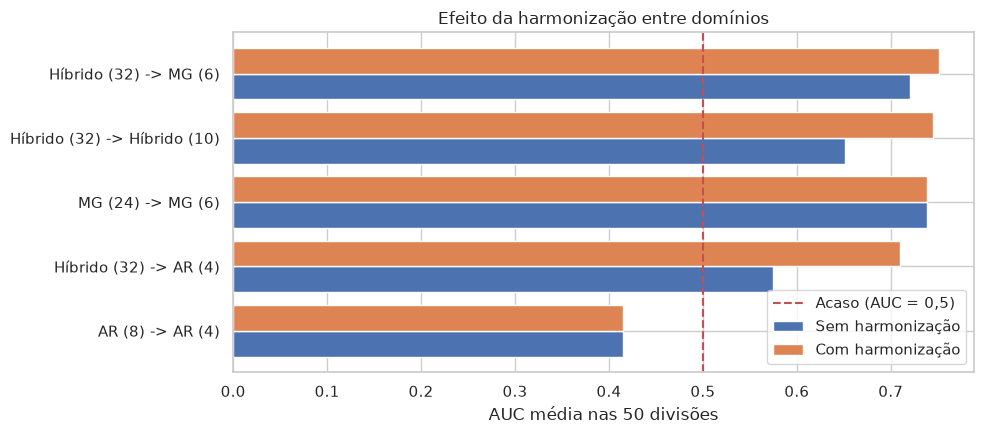

In [17]:
def harmonize_by_batch(X_train, X_test, batch_train, batch_test):
    """Centra e escala cada feature dentro de cada coorte usando só o treino."""
    X_train_h = X_train.copy().astype(float)
    X_test_h = X_test.copy().astype(float)
    for batch in np.unique(np.asarray(batch_train)):
        train_mask = np.asarray(batch_train) == batch
        mean = X_train.loc[train_mask].mean(axis=0)
        std = X_train.loc[train_mask].std(axis=0, ddof=0).replace(0, 1.0)
        X_train_h.loc[train_mask] = (X_train.loc[train_mask] - mean) / std
        test_mask = np.asarray(batch_test) == batch
        if test_mask.any():
            X_test_h.loc[test_mask] = (X_test.loc[test_mask] - mean) / std
    return X_train_h, X_test_h


def can_harmonize(batch_train, batch_test):
    """Só harmoniza se o lote do teste estiver presente no treino."""
    return set(pd.unique(batch_test)).issubset(set(pd.unique(batch_train)))


def evaluate_harmonized(name, config_train_idx, config_test_idx):
    """Ajusta harmonização e pipeline no treino e avalia no teste."""
    batch_train = meta_all["dataset"].iloc[config_train_idx]
    batch_test = meta_all["dataset"].iloc[config_test_idx]
    if not can_harmonize(batch_train, batch_test):
        return None

    X_train_h, X_test_h = harmonize_by_batch(
        X_all.iloc[config_train_idx],
        X_all.iloc[config_test_idx],
        batch_train,
        batch_test,
    )
    fitted = make_lasso_svm("linear", C=1.0, alpha=0.05).fit(
        X_train_h, y_all.iloc[config_train_idx]
    )
    y_prob = fitted.predict_proba(X_test_h)[:, 1]
    y_pred = fitted.predict(X_test_h)
    y_true = y_all.iloc[config_test_idx].to_numpy()
    return {
        "configuracao": name,
        "n_train": len(config_train_idx),
        "n_test": len(config_test_idx),
        **_metrics(y_true, y_pred, y_prob),
    }


# Comparação na divisão principal.
base_fixed = ablation_results.set_index("configuracao")
fixed_rows = []
for name, (config_train, config_test) in ABLATION_CONFIGS.items():
    harmonized = evaluate_harmonized(name, config_train, config_test)
    fixed_rows.append(
        {
            "configuracao": name,
            "auc_sem": base_fixed.loc[name, "auc"],
            "auc_com": np.nan if harmonized is None else harmonized["auc"],
            "acc_sem": base_fixed.loc[name, "accuracy"],
            "acc_com": np.nan if harmonized is None else harmonized["accuracy"],
        }
    )
fixed_comparison = pd.DataFrame(fixed_rows)
fixed_comparison.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_comparacao_harmonizacao.csv", index=False
)
display(fixed_comparison.round(3))

# Holdout principal com o modelo congelado e harmonização.
X_train_h, X_test_h = harmonize_by_batch(
    X_train, X_test, meta_train["dataset"], meta_test["dataset"]
)
final_model_h = make_lasso_svm("linear", C=1.0, alpha=0.05).fit(
    X_train_h, y_train
)
y_prob_h = final_model_h.predict_proba(X_test_h)[:, 1]
y_pred_h = final_model_h.predict(X_test_h)
holdout_harm = _metrics(y_test, y_pred_h, y_prob_h)
auc_low_h, auc_high_h = bootstrap_auc_ci(y_test.values, y_prob_h)
print("Holdout híbrido com harmonização:")
for metric, value in holdout_harm.items():
    print(f"  {metric}: {value:.3f}")
print(f"  AUC IC95% bootstrap: [{auc_low_h:.3f}, {auc_high_h:.3f}]")

# Métricas por coorte com o mesmo modelo harmonizado.
harm_domain_rows = []
for domain in ["GSE106894", "GSE131703"]:
    mask = (meta_test["dataset"] == domain).to_numpy()
    y_true_d = y_test.to_numpy()[mask]
    y_pred_d = y_pred_h[mask]
    y_prob_d = y_prob_h[mask]
    low, high = bootstrap_auc_ci(y_true_d, y_prob_d)
    harm_domain_rows.append(
        {
            "coorte": domain,
            "n": int(mask.sum()),
            **_metrics(y_true_d, y_pred_d, y_prob_d),
            "auc_ci_low": low,
            "auc_ci_high": high,
        }
    )
harm_domain = pd.DataFrame(harm_domain_rows)
harm_domain.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_harmonizacao_holdout_coortes.csv", index=False
)
display(harm_domain.round(3))

# 50 divisões: reutiliza a AUC sem harmonização já calculada na Etapa 8.1.
harm_rows = []
for repetition, seed in enumerate(
    range(RANDOM_STATE, RANDOM_STATE + N_REPEATS)
):
    ar_tr, ar_te, mg_tr, mg_te = split_stratified_positions(
        y_all, N_AR, N_TEST_AR, N_TEST_MG, seed
    )
    hybrid_train = np.concatenate([ar_tr, mg_tr])
    hybrid_test = np.concatenate([ar_te, mg_te])
    configs = {
        "AR (8) -> AR (4)": (ar_tr, ar_te),
        "MG (24) -> MG (6)": (mg_tr, mg_te),
        "AR (8) -> MG (6)": (ar_tr, mg_te),
        "MG (24) -> AR (4)": (mg_tr, ar_te),
        "Híbrido (32) -> AR (4)": (hybrid_train, ar_te),
        "Híbrido (32) -> MG (6)": (hybrid_train, mg_te),
        "Híbrido (32) -> Híbrido (10)": (hybrid_train, hybrid_test),
    }
    for name, (config_train, config_test) in configs.items():
        harmonized = evaluate_harmonized(name, config_train, config_test)
        harm_rows.append(
            {
                "repeticao": repetition,
                "seed": seed,
                "configuracao": name,
                "auc_com": np.nan if harmonized is None else harmonized["auc"],
            }
        )

harm_sensitivity = sensitivity.merge(
    pd.DataFrame(harm_rows), on=["repeticao", "seed", "configuracao"], how="left"
).rename(columns={"auc": "auc_sem"})
harm_sensitivity = harm_sensitivity[
    ["repeticao", "seed", "configuracao", "auc_sem", "auc_com"]
]
harm_sensitivity.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_harmonizacao_sensibilidade.csv", index=False
)

def fraction_above(values):
    values = values.dropna()
    return np.nan if values.empty else (values > 0.5).mean()


harm_sensitivity_summary = (
    harm_sensitivity.groupby("configuracao")
    .agg(
        auc_sem_media=("auc_sem", "mean"),
        auc_sem_desvio=("auc_sem", "std"),
        auc_com_media=("auc_com", "mean"),
        auc_com_desvio=("auc_com", "std"),
        sem_acima_0_5=("auc_sem", fraction_above),
        com_acima_0_5=("auc_com", fraction_above),
    )
    .round(3)
)
harm_sensitivity_summary.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_harmonizacao_resumo.csv"
)
display(harm_sensitivity_summary)

# Gráfico: AUC média com e sem harmonização.
plot_data = harm_sensitivity_summary.dropna(subset=["auc_com_media"]).reset_index()
plot_data = plot_data.sort_values("auc_com_media")
positions = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(
    positions - 0.2,
    plot_data["auc_sem_media"],
    height=0.4,
    label="Sem harmonização",
    color="#4c72b0",
)
ax.barh(
    positions + 0.2,
    plot_data["auc_com_media"],
    height=0.4,
    label="Com harmonização",
    color="#dd8452",
)
ax.set_yticks(positions)
ax.set_yticklabels(plot_data["configuracao"])
ax.axvline(0.5, color="#c44e52", linestyle="--", label="Acaso (AUC = 0,5)")
ax.set_xlabel("AUC média nas 50 divisões")
ax.set_title("Efeito da harmonização entre domínios")
ax.legend()
plt.tight_layout()
plt.show()


### Leitura

Na divisão principal, harmonizar leva Híbrido→Híbrido de 0,760 para 0,920 e Híbrido→MG de 0,667 para 0,889; Híbrido→AR já estava em 1,000. AR→AR e MG→MG não mudam, como esperado, porque o treino tem uma coorte só.

Nas 50 divisões o ganho que se sustenta é nos cenários híbridos: Híbrido→Híbrido 0,651 → 0,745, Híbrido→AR 0,575 → 0,710 e Híbrido→MG 0,720 → 0,751. A fração de divisões acima de 0,5 no híbrido sobe de 76% para 92%.

AR→MG e MG→AR ficam sem harmonização porque o lote do teste não aparece no treino. E o ponto principal continua: como lote = doença (plataforma/tecido confundidos), o ganho pode ser remoção de estrutura de coorte, não transferência biológica. A harmonização ajuda a testar a hipótese técnica, mas não substitui uma coorte externa.

Para separar de fato, seria preciso mais de um dataset por doença, as duas doenças na mesma plataforma/tecido, ou uma coorte externa medida no mesmo lote.


## Etapa 13 — Conclusão final

O modelo não mostra uma assinatura de resposta que generalize entre AR e MG; o desempenho só fica acima do acaso quando treino e teste compartilham a mesma coorte, e o desenho atual não permite saber se o que sobra é limitação técnica ou biológica.

A validação interna fica perto do acaso (CV AUC 0,539; LOOCV 0,523), e os cenários de troca de doença também (MG→AR 0,500; AR→MG 0,509). O desempenho melhora quando treino e teste vêm da mesma coorte: MG→MG 0,738 e Híbrido→Híbrido 0,651 nas 50 divisões. O holdout de 0,760 é um sorteio favorável; a média das 50 divisões é a leitura mais realista.

A normalização por amostra e a harmonização por lote melhoram os cenários híbridos (com harmonização, Híbrido→Híbrido 0,745), mas não mudam os cenários de troca de doença. Isso sugere que parte do ganho vem de deixar as coortes mais comparáveis, não de uma biologia de resposta compartilhada.

Não dá para separar esses dois efeitos com os dados atuais. Cada doença veio de uma única coorte (AR = GSE106894/Affymetrix/PBMC; MG = GSE131703/miRNA-seq/sangue total), então lote e doença são a mesma variável. Uma melhora após harmonização pode ser correção de plataforma/tecido, e AR→MG/MG→AR não puderam nem ser harmonizados porque o lote do teste não aparece no treino.

As limitações são o n pequeno (4 e 6 amostras no teste), as plataformas/tecidos diferentes, o confundimento total entre lote e doença e os hiperparâmetros fixos. O próximo passo decisivo seria uma coorte externa ou mais de um dataset por doença; sem isso, ComBat/harmony e modelos não lineares ajudam a explorar, mas não resolvem o confundimento.
